# Clean RGB oscillation workflow: `rgb_1m_z0p0142_10r`

This notebook prepares an adiabatic, nonrotating GYRE calculation from one
MESA pulse-data snapshot. It uses separate radial and nonradial scans for the
asteroseismology option because red-giant mixed modes are far denser than
radial modes. The legacy notebooks were instead oriented toward quadrupolar
tidal/TDE modes (`l=2`); select that intent explicitly in the parameter cell.

`RUN_GYRE` is `False` by default. Opening or running all cells therefore does
not launch GYRE or overwrite results.

## Expected inputs and outputs

Run the notebook from anywhere inside this clone. The shared implementation
is in `scripts/run_gyre/pipeline/`; generated products go to
`results/run_gyre/rgb_clean/<case>/<scan>/`.

The repository does **not** contain the stellar pulse file. Copy the matching
MESA export into `models/` (or edit `MODEL_PATH` below). It must be written
with `pulse_data_format = 'GYRE'`; an ordinary `profile*.data` is not a
replacement.

After supplying a model and GYRE, set `RUN_GYRE=True`, restart the kernel, and
run all cells. Keep `OVERWRITE=False` unless replacing a pipeline-created run
is intentional.

In [1]:
from pathlib import Path
import sys
import os

os.environ["GYRE_DIR"] = "/Users/mchau/gyre-9.1.1"

from pathlib import Path

MODEL_PATH = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/"
    "models/RGB1Msun_Z0p0142_logR1p0.mesa"
)

def locate_repo_root(start):
    for candidate in (start, *start.parents):
        marker = candidate / "scripts" / "run_gyre" / "pipeline" / "rgb_cases.py"
        if marker.is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the cloned repository.")

REPO_ROOT = locate_repo_root(Path.cwd().resolve())
PIPELINE_DIR = REPO_ROOT / "scripts" / "run_gyre" / "pipeline"
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

from gyre_pipeline import render_gyre_input
from rgb_cases import (
    build_run_configs,
    case_paths,
    configure_plot_style,
    get_case,
    load_case_summaries,
    mode_quality_report,
    plot_eigenfunctions,
    plot_mode_spectrum,
    preflight_case,
    run_case_plan,
    stellar_parameter_report,
)

configure_plot_style()

## Editable parameters

Use `SCIENCE_MODE="asteroseismology"` for `l=0,1,2` starting scans. Use
`"quadrupole_tides"` to reproduce the legacy degree choice (`l=2` only).
Neither preset proves completeness: widen the order bounds and increase scan
and spatial resolution until scientifically important frequencies converge.

In [2]:
CASE_KEY = "rgb_1m_z0p0142_10r"
CASE = get_case(CASE_KEY)

# Repository-relative defaults. Absolute paths are also accepted.
MODEL_PATH = Path("models") / CASE.model_filename
OUTPUT_ROOT = Path("results/run_gyre/rgb_clean") / CASE.key
GYRE_EXECUTABLE = None  # Example: Path("/path/to/gyre/bin/gyre"); otherwise use $GYRE_DIR.

RUN_GYRE = True
OVERWRITE = True
SCIENCE_MODE = "asteroseismology"  # Or "quadrupole_tides" for legacy l=2/TDE intent.

# Starting values from the shared case definition; edit for convergence tests.
FREQ_MIN_UHZ, FREQ_MAX_UHZ = CASE.freq_min_uhz, CASE.freq_max_uhz
N_PG_MIN, N_PG_MAX = CASE.n_pg_min, CASE.n_pg_max
RADIAL_N_FREQ = CASE.radial_n_freq
NONRADIAL_N_FREQ = CASE.nonradial_n_freq
NONRADIAL_DEGREES = (1, 2)
NONRADIAL_GRID_TYPE = "INVERSE"
W_OSC, W_EXP, W_CTR = 10.0, 2.0, 100.0
THREADS = 1

In [3]:
MODEL_PATH, OUTPUT_ROOT = case_paths(
    REPO_ROOT, CASE, model_path=MODEL_PATH, output_root=OUTPUT_ROOT
)
print(CASE.label)
print(f"Expected model: {MODEL_PATH}")
print(f"Target radius: {CASE.radius_rsun:.4g} R_sun")
print(f"Starting frequency band: {FREQ_MIN_UHZ:g}--{FREQ_MAX_UHZ:g} microhertz")
print(f"Case note: {CASE.note}")

$1\,M_\odot$, $Z=0.0142$, $R\simeq10\,R_\odot$ RGB
Expected model: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/models/RGB1Msun_Z0p0142_logR1p0.mesa
Target radius: 10 R_sun
Starting frequency band: 250--500 microhertz
Case note: The broad band brackets the expected solar-like power region near tens of microhertz.


## Read-only preflight

In [4]:
preflight = preflight_case(
    REPO_ROOT,
    CASE,
    model_path=MODEL_PATH,
    output_root=OUTPUT_ROOT,
    gyre_executable=GYRE_EXECUTABLE,
)
for key in (
    "model_path", "model_available", "model_valid", "gyre_executable",
    "gyre_available", "output_root",
):
    print(f"{key}: {preflight[key]}")
for message in preflight["messages"]:
    print(f"NOTE: {message}")

model_path: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/models/RGB1Msun_Z0p0142_logR1p0.mesa
model_available: True
model_valid: True
gyre_executable: /Users/mchau/gyre-9.1.1/bin/gyre
gyre_available: True
output_root: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r


## Construct and inspect the scan plan

The radial scan is linear and modest. The nonradial scan is much finer and
inverse-frequency by default to better sample the g-mode-rich spectrum.
`w_ctr=100` deliberately resolves the compact RGB core more strongly than the
legacy `w_ctr=10`.

In [5]:
configs = build_run_configs(
    CASE,
    science_mode=SCIENCE_MODE,
    freq_min_uhz=FREQ_MIN_UHZ,
    freq_max_uhz=FREQ_MAX_UHZ,
    n_pg_min=N_PG_MIN,
    n_pg_max=N_PG_MAX,
    radial_n_freq=RADIAL_N_FREQ,
    nonradial_n_freq=NONRADIAL_N_FREQ,
    nonradial_degrees=NONRADIAL_DEGREES,
    nonradial_grid_type=NONRADIAL_GRID_TYPE,
    w_osc=W_OSC,
    w_exp=W_EXP,
    w_ctr=W_CTR,
    threads=THREADS,
)
for scan_name, config in configs.items():
    print(f"\n--- {scan_name} scan ---")
    print(render_gyre_input(config))


--- radial scan ---
&constants
/

&model
  model_type = 'EVOL'
  file = 'input_model.mesa'
  file_format = 'MESA'
/

&mode
  l = 0
  n_pg_min = -4000
  n_pg_max = 150
/

&osc
  outer_bound = 'VACUUM'
/

&rot
/

&num
  diff_scheme = 'COLLOC_GL4'
/

&scan
  grid_type = 'LINEAR'
  freq_min = 250
  freq_max = 500
  n_freq = 800
  freq_units = 'UHZ'
/

&grid
  w_osc = 10
  w_exp = 2
  w_ctr = 100
/

&ad_output
  summary_file = 'summary.h5'
  summary_item_list = 'id,l,n_pg,n_p,n_g,omega,freq,freq_units,E_norm,R_star,M_star,chi,n_iter'
  detail_template = 'detail.l%l.n%n.h5'
  detail_item_list = 'id,l,n_pg,omega,freq,x,xi_r,xi_h,c_1,As,V_2,Gamma_1,rho,M_r'
  freq_units = 'UHZ'
/

&nad_output
/


--- nonradial scan ---
&constants
/

&model
  model_type = 'EVOL'
  file = 'input_model.mesa'
  file_format = 'MESA'
/

&mode
  l = 1
  n_pg_min = -4000
  n_pg_max = 150
/
&mode
  l = 2
  n_pg_min = -4000
  n_pg_max = 150
/

&osc
  outer_bound = 'VACUUM'
/

&rot
/

&num
  diff_scheme = 'COLLOC_GL4'
/

## Opt-in execution

In [6]:
run_results = {}
if not RUN_GYRE:
    print("GYRE execution is disabled. Set RUN_GYRE=True only after preflight passes.")
elif not preflight["model_valid"]:
    raise FileNotFoundError(
        f"Supply a valid MESA GYRE-format pulse model first: {MODEL_PATH}"
    )
elif not preflight["gyre_available"]:
    raise FileNotFoundError("Set GYRE_EXECUTABLE or export GYRE_DIR before running.")
else:
    run_results = run_case_plan(
        MODEL_PATH,
        OUTPUT_ROOT,
        configs,
        gyre_executable=GYRE_EXECUTABLE,
        overwrite=OVERWRITE,
        dry_run=False,
    )
    for scan_name, result in run_results.items():
        print(f"{scan_name}: {result.output_dir}")

radial: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r/radial
nonradial: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r/nonradial


## Load and validate available mode catalogues

In [7]:
summaries = load_case_summaries(OUTPUT_ROOT, tuple(configs))
if not summaries:
    print("No summary files yet; complete a real GYRE run first.")
else:
    for scan_name, summary in summaries.items():
        report = mode_quality_report(summary, configs[scan_name])
        stellar = stellar_parameter_report(summary, CASE)
        print(f"\n{scan_name}: {report['mode_count']} modes")
        print(f"by degree: {report['by_degree']}")
        print(f"max chi: {report['max_chi']}; max n_iter: {report['max_n_iter']}")
        print(f"model mass: {stellar['mass_msun']} M_sun; radius: {stellar['radius_rsun']} R_sun")
        for warning in stellar["warnings"]:
            print(f"WARNING: {warning}")
        if report["warnings"]:
            for warning in report["warnings"]:
                print(f"WARNING: {warning}")
        else:
            print("No automated quality warnings.")


radial: 55 modes
by degree: {0: {'count': 55, 'n_pg_min_found': 55, 'n_pg_max_found': 109, 'duplicate_steps': 0, 'nonmonotonic_steps': 0}}
max chi: 4.593818713366764e-13; max n_iter: 6
model mass: 0.9999697610213131 M_sun; radius: 10.003712895404544 R_sun
No automated quality warnings.

nonradial: 199 modes
by degree: {1: {'count': 87, 'n_pg_min_found': -10, 'n_pg_max_found': 77, 'duplicate_steps': 0, 'nonmonotonic_steps': 0}, 2: {'count': 112, 'n_pg_min_found': -58, 'n_pg_max_found': 53, 'duplicate_steps': 0, 'nonmonotonic_steps': 0}}
max chi: 1.3809047708166022e-10; max n_iter: 9
model mass: 0.9999697610213131 M_sun; radius: 10.003712895404544 R_sun
No automated quality warnings.


## Mode spectrum

The figure is intentionally title-free and is saved as PDF and 300-dpi PNG
only when real summaries exist. A clean diagnostic requires monotonically
increasing `n_pg` with frequency within each `l`, no order-boundary hits, and
stable frequencies when `n_freq`, `w_osc`, and `w_ctr` are increased.

Saved:
  /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r/mode_spectrum.pdf
  /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r/mode_spectrum.png


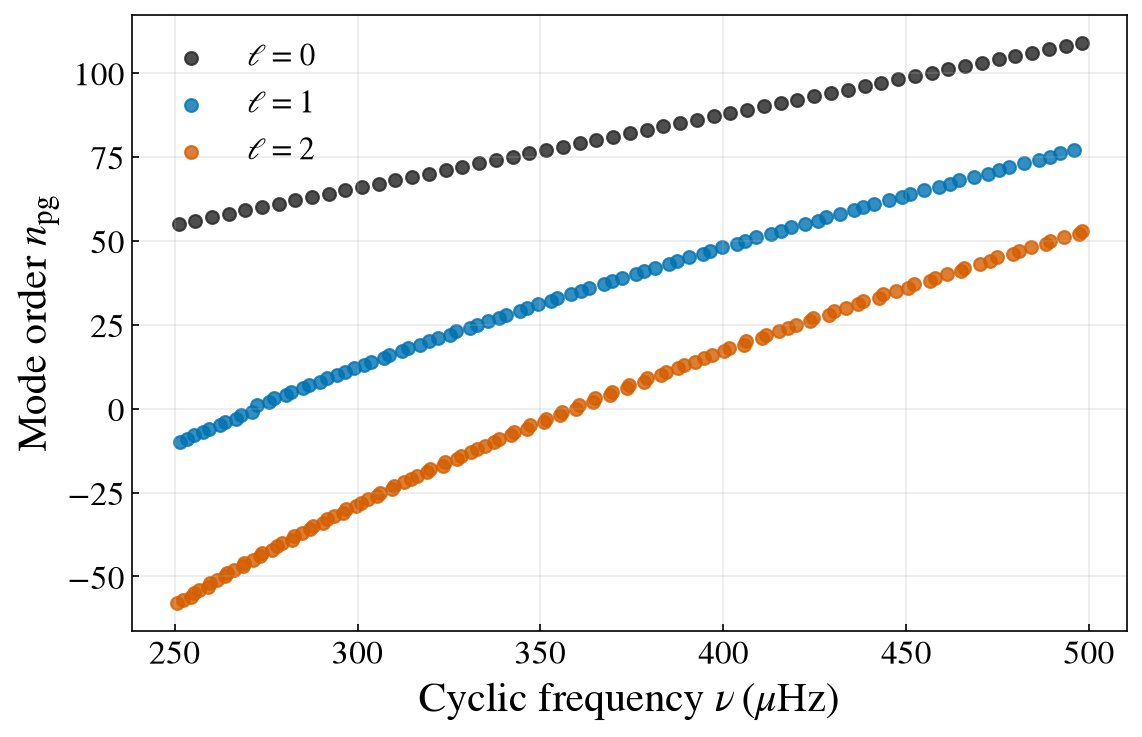

In [8]:
if summaries:
    fig, ax, saved = plot_mode_spectrum(
        summaries, output_prefix=OUTPUT_ROOT / "mode_spectrum"
    )
    print("Saved:", *(str(path) for path in saved), sep="\n  ")
else:
    print("Spectrum plot skipped: no summaries are available.")

## One mode's eigenfunctions

In [9]:
detail_files = []
for scan_name in configs:
    detail_files.extend(sorted((OUTPUT_ROOT / scan_name).glob("detail.id*.l*.n*.h5")))

if detail_files:
    DETAIL_INDEX = 0  # Edit to inspect another mode.
    selected_detail = detail_files[DETAIL_INDEX]
    fig, ax, saved = plot_eigenfunctions(
        selected_detail, output_prefix=OUTPUT_ROOT / "eigenfunctions"
    )
    print(f"Selected: {selected_detail}")
    print("Saved:", *(str(path) for path in saved), sep="\n  ")
else:
    print("Eigenfunction plot skipped: no detail files are available.")

Eigenfunction plot skipped: no detail files are available.


## Interpretation checklist

- Confirm `R_star` and `M_star` in the new summary match this case; never infer
  them from a notebook filename or old saved output.
- Treat an `n_pg` boundary hit, duplicate, or nonmonotonic sequence as a reason
  to widen/refine the search.
- Repeat with at least twice `NONRADIAL_N_FREQ` and increased `W_CTR`; retain
  only frequencies stable at the precision needed by the science.
- `quadrupole_tides` is an `l=2` catalogue, not a complete solar-like RGB
  spectrum. Asteroseismic interpretation needs the radial and dipole modes as
  well as careful completeness checks.
- These calculations are adiabatic and nonrotating; they do not predict mode
  damping, growth rates, or rotational splitting.

In [9]:
from pathlib import Path
import json

RUN_DIR = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/"
    "results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r"
)

for mode in ["radial", "nonradial"]:
    print("\n" + "=" * 60)
    print(f"{mode.upper()} RUN")
    print("=" * 60)

    metadata_file = RUN_DIR / mode / "run_metadata.json"

    print("File:", metadata_file)
    print("Exists:", metadata_file.exists())

    if not metadata_file.exists():
        continue

    with open(metadata_file, "r") as f:
        metadata = json.load(f)

    # Recursively search for stellar quantities
    def find_keys(obj, target_keys, path=""):
        if isinstance(obj, dict):
            for key, value in obj.items():
                current_path = f"{path}.{key}" if path else key

                if key in target_keys:
                    print(f"{current_path} = {value}")

                find_keys(value, target_keys, current_path)

        elif isinstance(obj, list):
            for i, value in enumerate(obj):
                find_keys(value, target_keys, f"{path}[{i}]")

    find_keys(
        metadata,
        {
            "M_star",
            "R_star",
            "m_star",
            "r_star",
            "mass",
            "radius",
            "mass_msun",
            "radius_rsun",
        },
    )


RADIAL RUN
File: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r/radial/run_metadata.json
Exists: True

NONRADIAL RUN
File: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r/nonradial/run_metadata.json
Exists: True


In [10]:
from pathlib import Path

RUN_DIR = Path(
    "/Users/mchau/mesa_tutorial/mesa-gyre-oscillations/"
    "results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r"
)

for mode in ["radial", "nonradial"]:
    model_file = RUN_DIR / mode / "input_model.mesa"

    print("\n" + "=" * 60)
    print(f"{mode.upper()} MODEL")
    print("=" * 60)
    print("File:", model_file)
    print("Exists:", model_file.exists())

    if model_file.exists():
        with open(model_file, "r") as f:
            lines = f.readlines()

        # Print the first ~10 lines, which contain the MESA/GYRE header
        print("\nModel header:")
        for line in lines[:10]:
            print(line.rstrip())


RADIAL MODEL
File: /Users/mchau/mesa_tutorial/mesa-gyre-oscillations/results/run_gyre/rgb_clean/rgb_1m_z0p0142_10r/radial/input_model.mesa
Exists: True

Model header:
  1486     1.9884098706980504E+33     6.9595830613329407E+11     1.5023459828894594E+35    101
     1     0.0000000000000000E+00     0.0000000000000000E+00     0.0000000000000000E+00     2.2212884830267203E+21     3.6208696232012577E+07     2.0437829810142959E+05     1.2261755153179649E-02     0.0000000000000000E+00     1.6284670826154306E+00     3.8807795929742384E-01     6.1264201336055139E-02     2.0006251556514788E-02     3.8345249802296526E-02    -3.5134820316798682E-02     7.5749018935518869E-07     3.4874717121175084E-06     7.2578115822441921E-07     0.0000000000000000E+00
     2     5.6615903649900984E+06     1.5535467714142269E+26     1.8689639381749755E+25     2.2211081980174858E+21     3.6208660670641623E+07     2.0436787029718241E+05     1.2262364984295499E-02     2.2143121989679306E-07     1.628468413285951